# Mapper de videos

Cada punto representa un video en sus **primeros siete días calendario**, del día 0 al 6. Cada curva se divide por su total semanal. El día 0 puede ser parcial. La distancia euclidiana se calcula entre los siete valores normalizados.

In [1]:
import csv
from pathlib import Path
from html import escape

raiz = Path.cwd()
if not (raiz / "datos").is_dir() and (raiz.parent / "datos").is_dir():
    raiz = raiz.parent
if not (raiz / "datos").is_dir():
    raise FileNotFoundError("Ejecuta el notebook desde la raíz del proyecto.")

def svg(contenido, ancho=850, alto=250):
    return (f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {ancho} {alto}" '
            f'width="{ancho}" height="{alto}" font-family="system-ui" font-size="13" fill="#18324a">'
            f'<rect width="100%" height="100%" fill="white"/>{contenido}</svg>')

def etiqueta(x, y, texto):
    return f'<text x="{x}" y="{y}">{escape(str(texto))}</text>'

def mostrar(grafico):
    try:
        from IPython.display import SVG, display
    except ImportError:
        return
    display(SVG(grafico))

import sys

sys.path.insert(0, str(raiz))
from Videos.mapper_videos import load_videos, mapper

metricas = (
    "Reproducciones de video de 3 segundos",
    "Segundos reproducidos",
    "Reacciones, comentarios y veces que se compartió",
)
fuente = raiz / "datos/transformados/series_diarias_por_video.csv"


## Selección y grafo

Cambia la métrica, la lente o el radio y ejecuta esta celda. Mapper crea intervalos solapados sobre la lente y agrupa por enlace simple dentro de cada intervalo. Una arista entre nodos indica que comparten un video.

27 videos, 3 excluidos, 6 nodos, 1 aristas


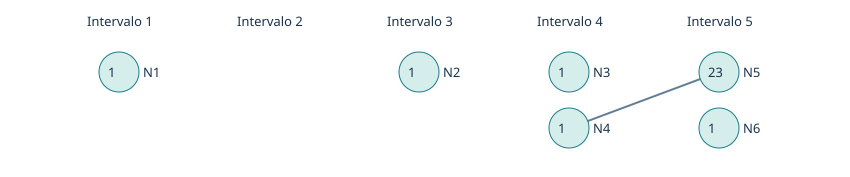

In [2]:

metrica = metricas[0]
lente = "inicio"  # "inicio", "dia_promedio" o "persistencia_h0"
intervalos, solapamiento, radio = 5, .35, .12
videos, excluidos = load_videos(fuente, metrica)
if lente == "dia_promedio":
    videos = [dict(v, lente=sum(dia*p for dia,p in enumerate(v["forma"]))) for v in videos]
elif lente == "persistencia_h0":
    from Videos.persistencia_semanal import con_lente_h0
    videos = con_lente_h0(videos)
elif lente != "inicio":
    raise ValueError("Elige inicio, dia_promedio o persistencia_h0")
grafo = mapper(videos, intervalos, solapamiento, radio)
nodos = grafo["nodos"]
print(f"{len(videos)} videos, {len(excluidos)} excluidos, {len(nodos)} nodos, {len(grafo['aristas'])} aristas")

columnas = [[i for i,n in enumerate(nodos) if n["intervalo"] == j]
            for j in range(1, intervalos+1)]
paso = 750 / intervalos
posiciones = {i:(44+paso*(j+.5),72+56*k)
              for j,columna in enumerate(columnas) for k,i in enumerate(columna)}
contenido = ""
for j, columna in enumerate(columnas):
    contenido += etiqueta(44+paso*(j+.5)-32, 26, f"Intervalo {j+1}")
for arista in grafo["aristas"]:
    x1,y1 = posiciones[arista["a"]]
    x2,y2 = posiciones[arista["b"]]
    contenido += f'<path d="M{x1} {y1} L{x2} {y2}" stroke="#647e95" stroke-width="2"/>'
for i,nodo in enumerate(nodos):
    x,y = posiciones[i]
    cantidad = len(nodo["videos"])
    contenido += f'<circle cx="{x}" cy="{y}" r="20" fill="#d5eeec" stroke="#187c87"/>'
    contenido += etiqueta(x-11, y+5, cantidad) + etiqueta(x+24,y+5,f"N{i+1}")
grafico = svg(contenido, alto=65+56*max(map(len,columnas)))
mostrar(grafico)


## Trayectorias de un nodo

Por defecto se muestra el nodo con más integrantes. Puedes indicar un número de nodo para ver cada curva y su volumen semanal. El eje vertical muestra la fracción del total semanal.

Nodo 5 · 23 videos
Video                 Total semanal    Lente
27002385192792689          3,512.00    87.2%
1409322527468624           1,981.00    88.3%
2055094155163243           1,857.00    83.6%
1477519340898472           1,835.00    88.4%
1635669464946133           1,651.00    86.5%
1651252596718307           1,587.00    92.1%
4238377379781430           1,478.00    90.5%
1627823882401458           1,373.00    90.5%
1744465346627793           1,198.00    94.1%
1125591856554489           1,151.00    95.0%
4600843343568884           1,096.00    74.9%
1691970072362772           1,038.00    89.3%
2214230539496889             938.00    91.3%
1441826411471662             878.00    88.2%
1057441153999497             844.00    92.4%
1428108932826254             776.00    93.9%
1646725340318423             717.00    84.7%
1111080558344317             578.00    88.4%
1589278979613662             490.00    86.9%
1845501500212804             466.00    89.3%
2914033295627273             399.00 

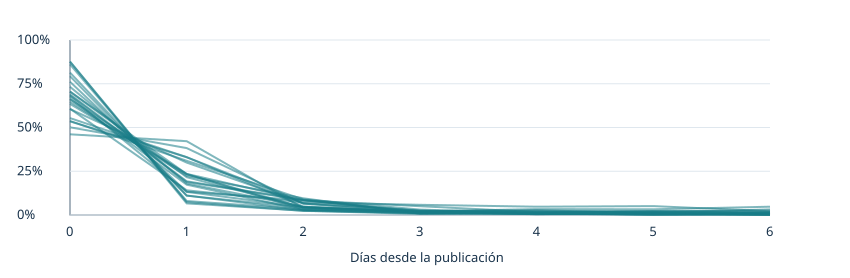

In [3]:

numero_nodo = None  # Por ejemplo, 1 para inspeccionar N1.
indice = (max(range(len(nodos)),key=lambda i:len(nodos[i]["videos"]))
          if numero_nodo is None else numero_nodo-1)
if not 0 <= indice < len(nodos):
    raise ValueError("Indica un nodo presente en el grafo")
miembros = [videos[i] for i in nodos[indice]["videos"]]
print(f"Nodo {indice+1} · {len(miembros)} videos")
contenido = '<path d="M70 40 V215 H770" stroke="#52697d" fill="none"/>'
for porcentaje in (0, 25, 50, 75, 100):
    y = 215-1.75*porcentaje
    contenido += etiqueta(17,y+4,f"{porcentaje}%")
    contenido += f'<path d="M70 {y} H770" stroke="#dfe7ee"/>'
for dia in range(7):
    contenido += etiqueta(66+700*dia/6,236,dia)
contenido += etiqueta(350,262,"Días desde la publicación")
for v in miembros:
    coordenadas = " ".join(f"{70+700*i/6:.1f},{215-175*p:.1f}" for i,p in enumerate(v["forma"]))
    contenido += f'<polyline points="{coordenadas}" fill="none" stroke="#187c87" stroke-opacity="0.55" stroke-width="2"/>'
grafico = svg(contenido, alto=278)
mostrar(grafico)
print("Video                 Total semanal    Lente")
for v in sorted(miembros, key=lambda v: -v["total"]):
    valor = f'{v["lente"]:.1%}' if lente != "dia_promedio" else f'{v["lente"]:.2f} días'
    print(f'{v["id"]:20}  {v["total"]:13,.2f}    {valor}')


Con la configuración inicial de reproducciones, el nodo mayor reúne **23 de 27 videos**. El video `1111200735143753` forma un nodo propio y registra solo **10,2 %** de su total semanal en los días 0 y 1, aunque lidera el volumen de esos dos días. Tres videos quedaron fuera por cobertura incompleta al cierre de la exportación.

[Grafo interactivo para inspeccionar nodos](mapper_videos.html) · [Metodología de Mapper](metodologia_mapper_videos.md)

## Persistencia de repuntes semanales

En la filtración por superniveles, un pico abre una componente y el valle que la conecta con un pico más alto determina su fusión. La diferencia de alturas es la persistencia del pico secundario. El máximo global corresponde a la componente esencial. La lente de Mapper usa la mayor persistencia finita dividida por el total semanal. Una curva sin barras finitas positivas recibe cero. Los extremos de la ventana pueden generar barras y se señalan como tales.


Proporción inicial: 6 nodos, 1 aristas, nodo mayor de 23
Persistencia H0: 6 nodos, 1 aristas, nodo mayor de 23
Barras finitas positivas: 22 de 27
ID del video        Semana    Día del pico   Persistencia   Borde
1128917252962084        1763             4         13.7%   False
1111200735143753      134422             6          4.9%   True
1845501500212804         466             6          2.8%   True
2055094155163243        1857             6          2.7%   True
1082041734635757        6672             6          1.9%   True
4238377379781430        1478             6          1.5%   True
2914033295627273         399             6          1.0%   True
1420499806709754         363             4          0.8%   False


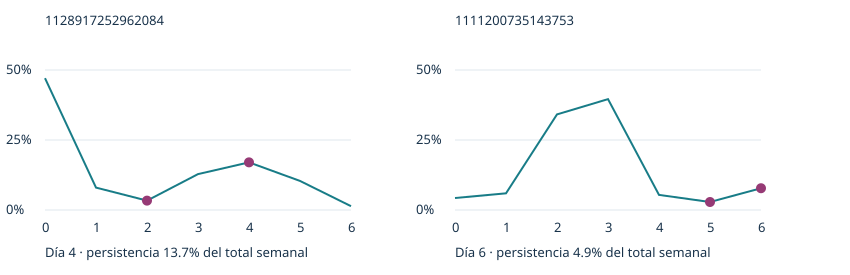

In [4]:
from Videos.persistencia_semanal import con_lente_h0

reproducciones, _ = load_videos(fuente, metricas[0])
videos_h0 = con_lente_h0(reproducciones)
orden = sorted(videos_h0, key=lambda video: -video["lente"])
grafo_h0 = mapper(videos_h0, 5, .35, .12)
base = mapper(reproducciones, 5, .35, .12)
for nombre, red in [("Proporción inicial", base), ("Persistencia H0", grafo_h0)]:
    mayor = max(len(nodo["videos"]) for nodo in red["nodos"])
    print(f"{nombre}: {len(red['nodos'])} nodos, {len(red['aristas'])} aristas, nodo mayor de {mayor}")
print(f"Barras finitas positivas: {sum(bool(video['barras_h0']) for video in videos_h0)} de {len(videos_h0)}")
print("ID del video        Semana    Día del pico   Persistencia   Borde")
for video in orden[:8]:
    dia, valle, diferencia = video["barras_h0"][0]
    print(f"{video['id']:20} {video['total']:7.0f} {dia:13} {video['lente']:13.1%}   {dia in (0, 6)}")

contenido = ""
for panel, video in enumerate(orden[:2]):
    izquierda = 45 + 410 * panel
    def x(dia):
        return izquierda + 51 * dia

    def y(valor):
        return 210 - 140 * valor / .5

    dia, valle, diferencia = video["barras_h0"][0]
    contenido += etiqueta(izquierda, 25, video["id"])
    for marca in (0, .25, .5):
        altura = y(marca)
        contenido += etiqueta(izquierda-39, altura+4, f"{marca:.0%}")
        contenido += f'<path d="M{x(0)} {altura} H{x(6)}" stroke="#dfe7ee"/>'
    coordenadas = " ".join(f"{x(d)},{y(valor)}" for d, valor in enumerate(video["forma"]))
    contenido += f'<polyline points="{coordenadas}" fill="none" stroke="#187c87" stroke-width="2"/>'
    for d in range(7):
        contenido += etiqueta(x(d)-3, 232, d)
    for d in (dia, valle):
        contenido += f'<circle cx="{x(d)}" cy="{y(video["forma"][d])}" r="5" fill="#963a75"/>'
    contenido += etiqueta(izquierda, 257, f"Día {dia} · persistencia {video['lente']:.1%} del total semanal")
grafico = svg(contenido, alto=275)
mostrar(grafico)


El mayor repunte secundario normalizado corresponde a un video de **1.763 reproducciones**. Subió de 59 en el día 2 a 300 en el día 4. El video de **134.422 reproducciones** tuvo su máximo global el día 3 y su barra finita más persistente en el día 6, al borde de la ventana. Esa barra describe el repunte observado hasta el corte semanal.

Con cinco intervalos, 35 % de solapamiento y radio 0,12, ambas lentes producen seis nodos y una arista. El nodo mayor sigue reuniendo 23 videos. La persistencia distingue repuntes individuales, aunque con esta configuración el grafo sigue concentrado.
